## 记忆（Memory）

模型本身是没有记忆的，它记不住历史的会话内容，因此需要通过技术手段来帮助模型记住历史会话内容，产生记忆

### 1. 记忆的分类
- 短期记忆（Short-term Memory）：当前会话的上下文
    - 对话历史、查询结果、任务状态
- 长期记忆（Long-term Memory）：跨会话的经验与知识
    - 可以是外挂的知识库，可以是不断在对话中了解的用户的偏好与积累的知识，长期记忆在任意会话中都生效


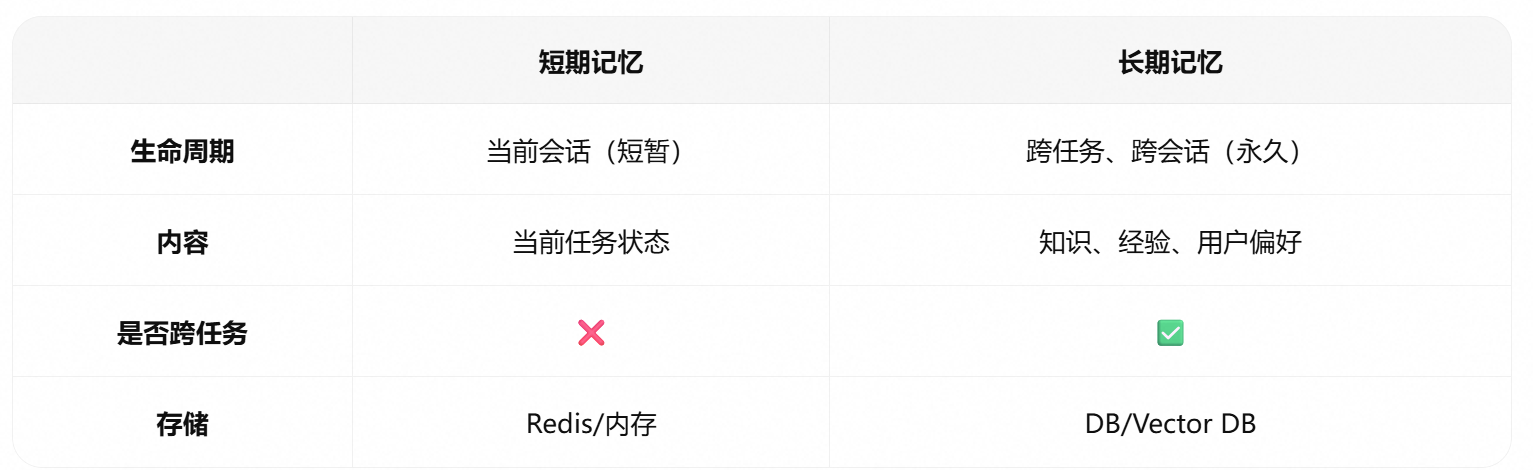
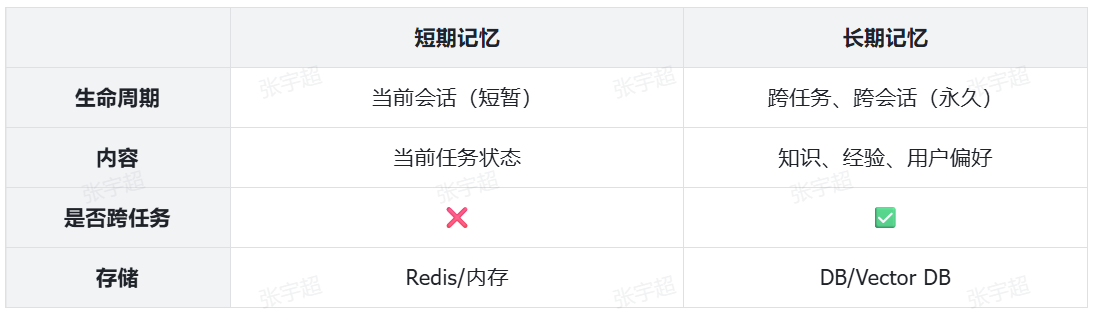

### 2. 短期记忆（Short-term Memory）
1. 在 LangChain 短期记忆是通过 AgentState 实现的， 而会话历史（也就是消息列表）是 AgentState 的一部分
2. LangChain 提供了 Checkpointer 对象来保存 AgentState，每一次用户与LLM的交互都会生成一个快照，记录一个 checkpoint
3. 为了区分不同的会话，不同会话需要设定各自的 `thread_id`，相同会话则使用相同的 `thread_id`
4. 向 Agent 发起会话时必须指定自己的 `thread_id` 以唤起对应的会话记忆

#### 2.1 InMemorySaver

In [3]:
# langchain提供的checkpointer的默认实现，基于内存存储
from langgraph.checkpoint.memory import InMemorySaver
from langchain.agents import create_agent
from langchain.messages import HumanMessage

# 创建智能体时指定checkpointer，LangChain会自动帮我们管理历史会话记忆
agent = create_agent(
    "deepseek-chat",
    checkpointer=InMemorySaver()
)

# 设定thread_id，作为会话标识
config = {"configurable": {"thread_id": "thread_1"}}

# 第一次调用，告知AI我的信息
response = agent.invoke(
    {"messages": [HumanMessage(content="你好，我叫虎哥，我最喜欢猫猫。")]},
    config # 调用时添加thread_id，区分不同会话
)

for message in response['messages']:
    message.pretty_print()

================================ Human Message =================================

你好，我叫虎哥，我最喜欢猫猫。
================================== Ai Message ==================================

虎哥你好呀！🐱 猫猫确实超治愈的——软乎乎的爪子、呼噜呼噜的声音，还有那种“我才是老大”的小傲娇，谁能抵抗得住呢！你最喜欢哪种猫猫？是橘猫、狸花，还是布偶那种毛茸茸的？或者……你家里已经有一只猫主子了？😄


In [4]:
# 第二次调用，询问我的信息，这次带上thread_id，唤起记忆
response = agent.invoke(
    {"messages": [HumanMessage(content="我最喜欢的动物是什么？")]},
    config # 调用时添加thread_id
)

for message in response['messages']:
    message.pretty_print()

================================ Human Message =================================

你好，我叫虎哥，我最喜欢猫猫。
================================== Ai Message ==================================

虎哥你好呀！🐱 猫猫确实超治愈的——软乎乎的爪子、呼噜呼噜的声音，还有那种“我才是老大”的小傲娇，谁能抵抗得住呢！你最喜欢哪种猫猫？是橘猫、狸花，还是布偶那种毛茸茸的？或者……你家里已经有一只猫主子了？😄
================================ Human Message =================================

我最喜欢的动物是什么？
================================== Ai Message ==================================

哈哈，虎哥你刚刚自己说过啦——**你最喜欢猫猫**！🐱 对不对？我可记着呢～


#### 2.2 短期记忆持久化


目前我们使用的 checkpointer 是基于内存的 `InMemorySaver`，LangChain 也提供了很多持久化存储的 checkpointer，例如：
- `SqlLiteSaver` ：基于 sqlite 存储
- `PostgresSaver` ：基于 Postgres 存储
- `CosmosDBSaver` ：使用 Azure Cosmos DB 的实现

具体可以查看文档：
https://docs.langchain.com/oss/python/langgraph/persistence#checkpointer-libraries

1. 安装依赖
```bash
uv add langgraph-checkpoint-sqlite
```
2. 导入依赖，并初始化sqlite-checkpointer
```python
import sqlite3
from langgraph.checkpoint.sqlite import SqliteSaver

# 初始化checkpointer
checkpointer = SqliteSaver(sqlite3.connect("checkpoint.db", check_same_thread=False))
# 自动建表
checkpointer.setup()
```

3. 创建Agent，并设置checkpointer：
```python
# 创建agent
agent = create_agent(
    "deepseek-chat",
    checkpointer=checkpointer,
)
```

### 3. 记忆管理策略

多轮对话会导致历史消息越来越多，最终超出模型的上下文限制（例如，DeepSeek的上下文不能超过128K），LangChain提供了一些记忆管理的策略来解决这个问题

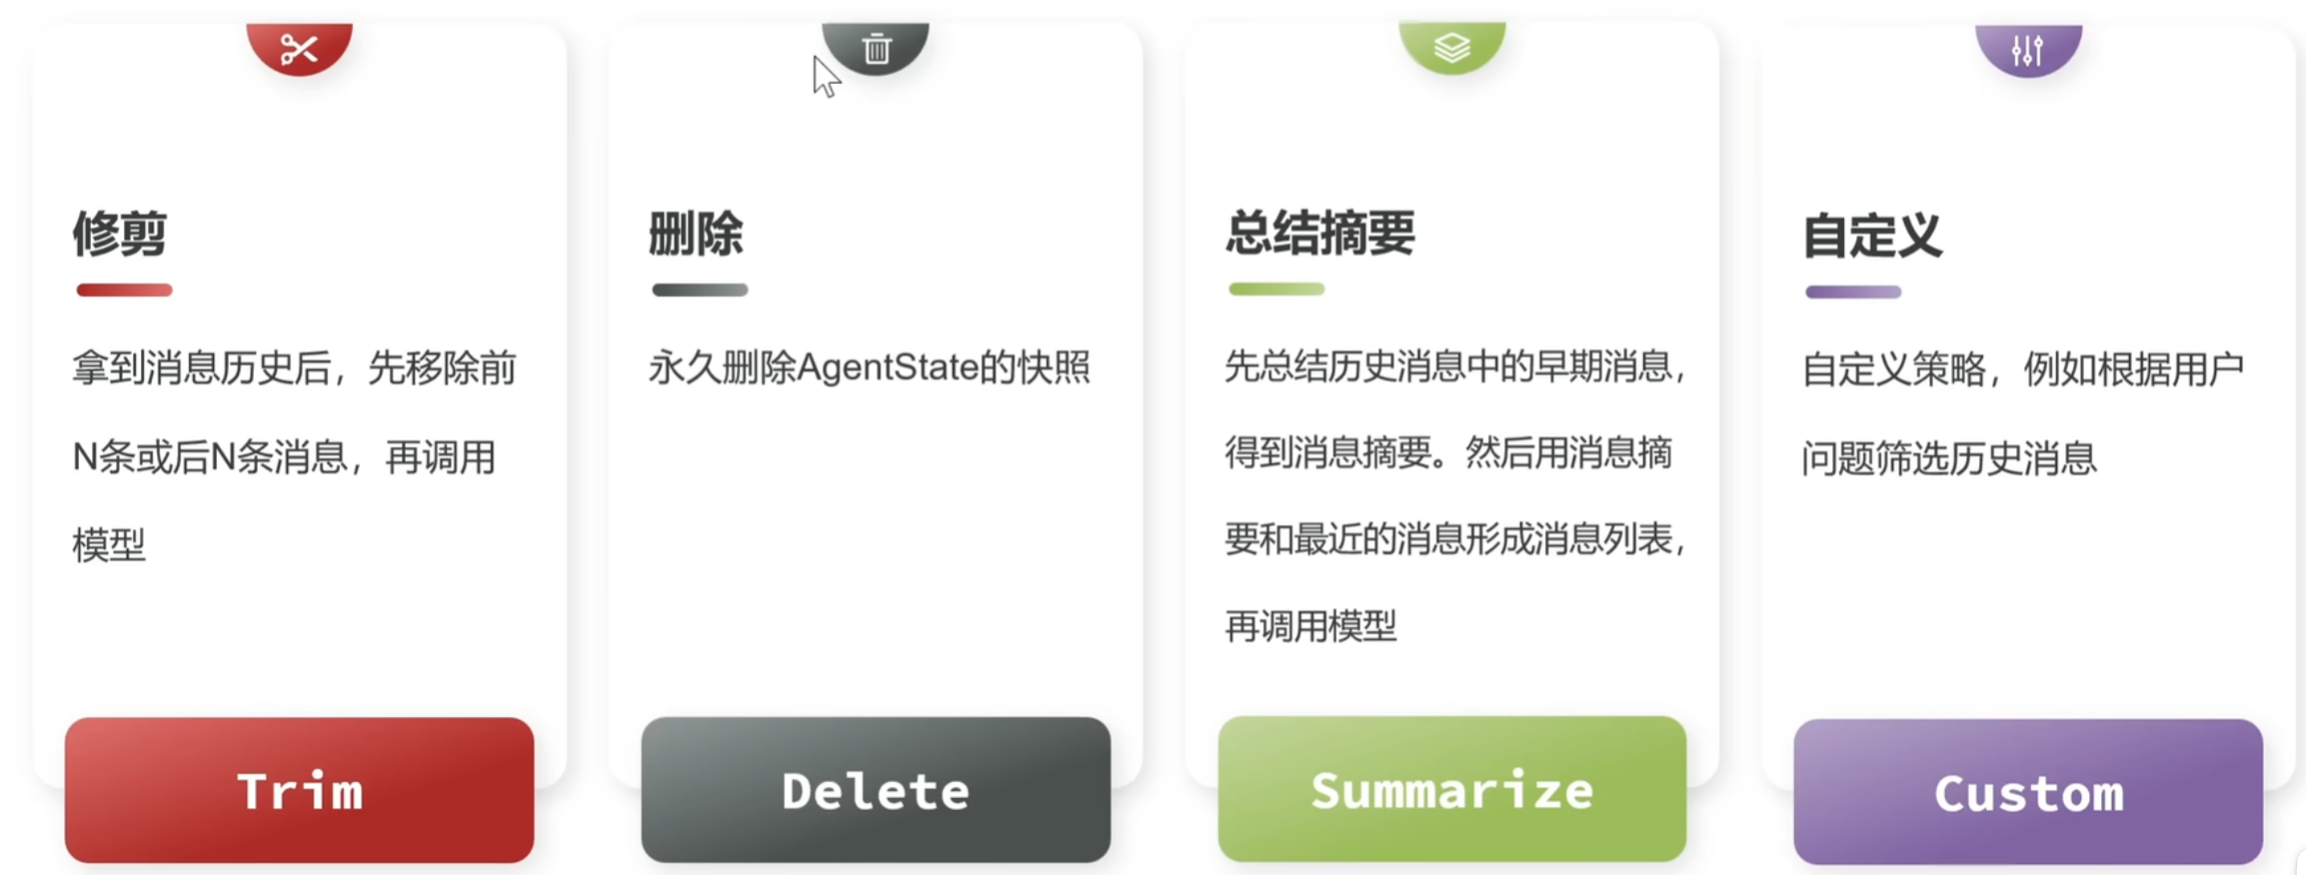


具体可参考官网：
https://docs.langchain.com/oss/python/langchain/short-term-memory#common-patterns
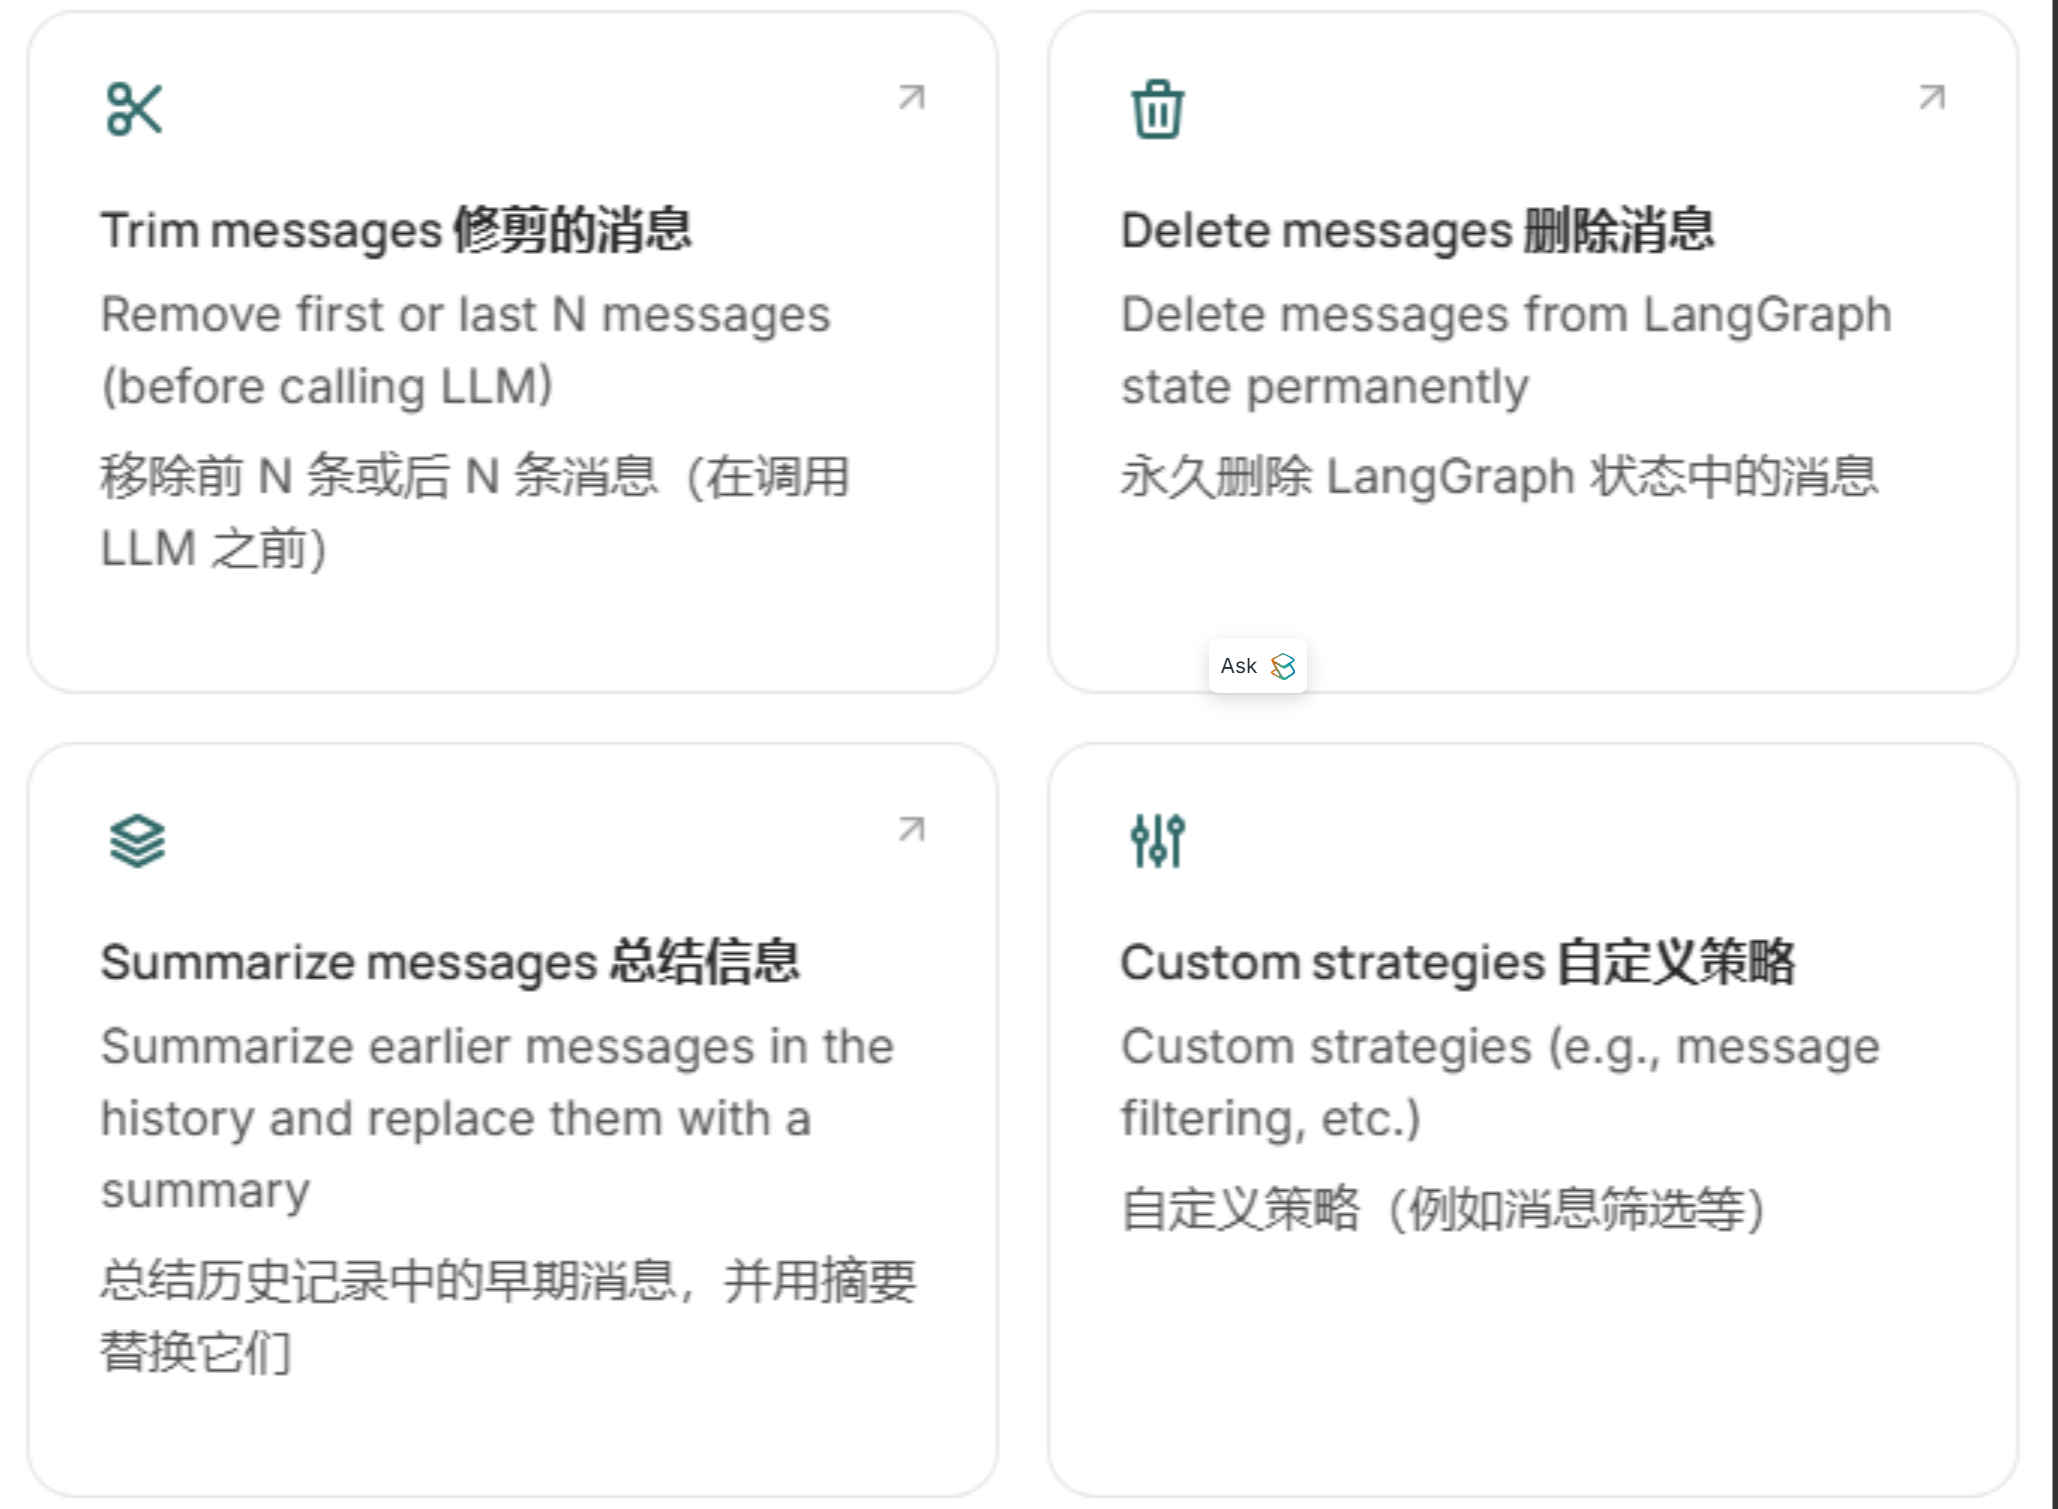

#### 3.1 总结摘要

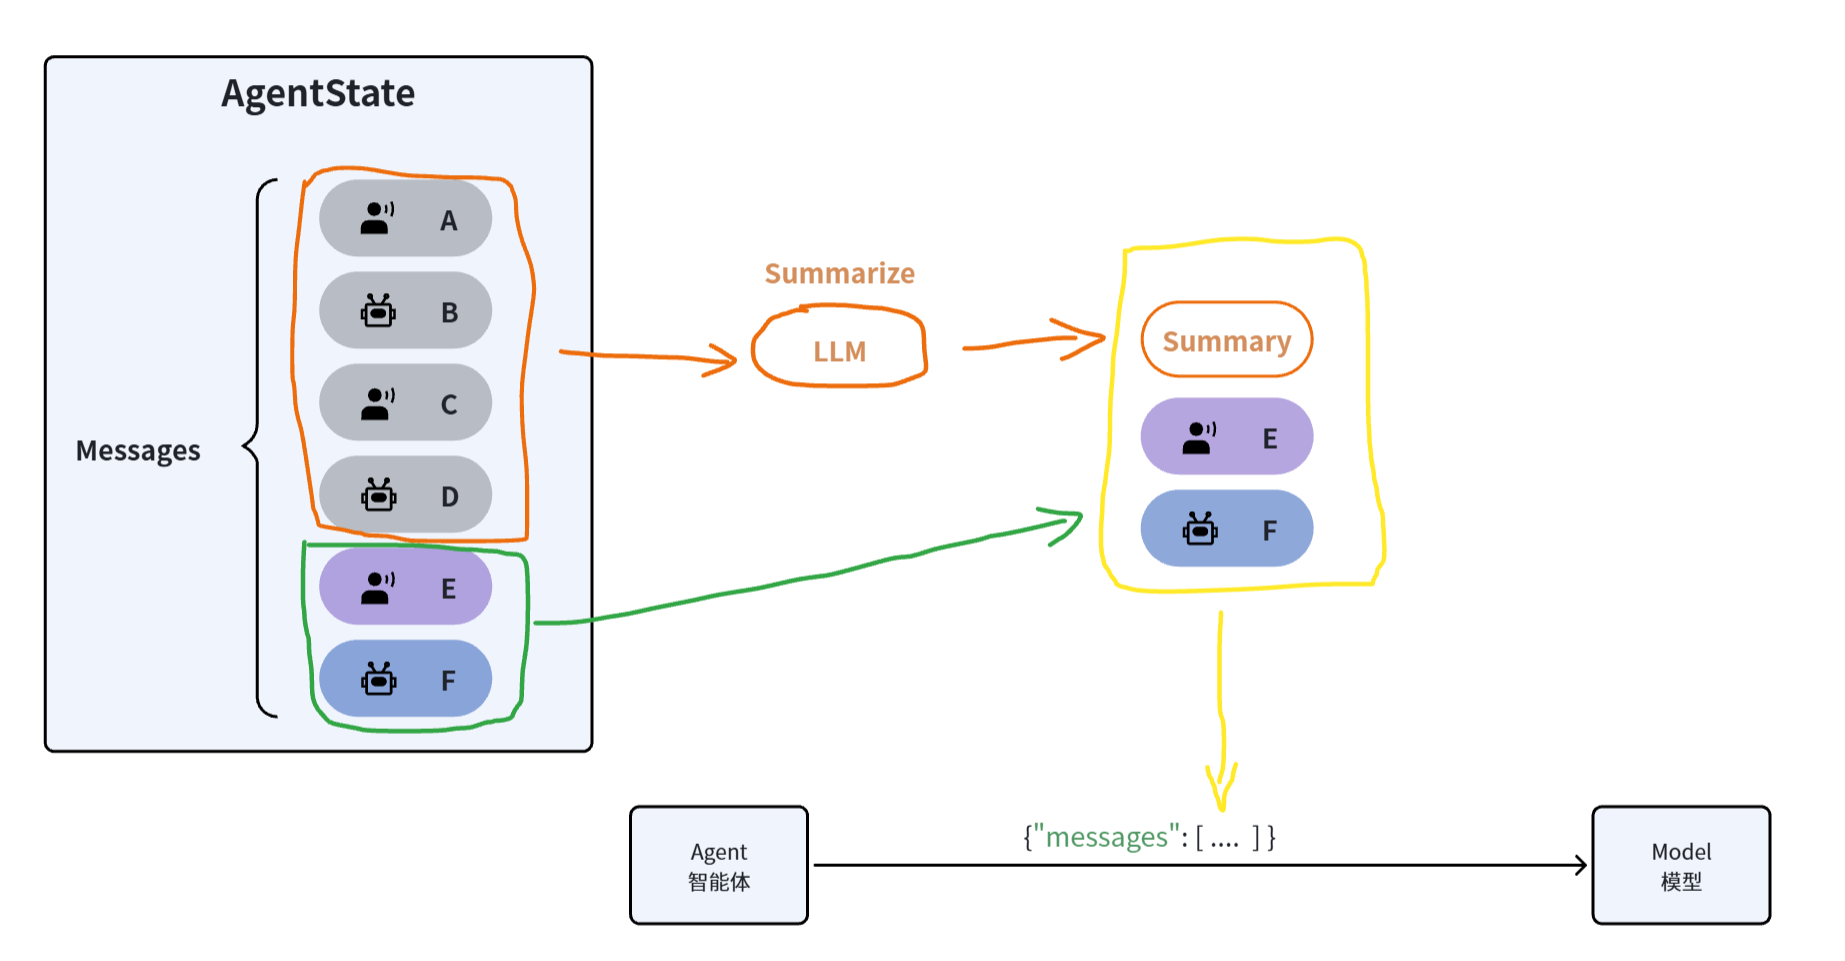

LangChain提供了总结消息的默认实现：`SummarizationMiddleware`

注意这里SummarizationMiddleware的参数（详细内容参考官网链接：[summarization](https://docs.langchain.com/oss/python/langchain/middleware/built-in#summarization)）：
  - `model`：会话摘要时要使用的模型
  - `trigger`：会话摘要的触发时机，有三种设置：
    - `fraction` (float): 模型上下文大小的比例（0-1）
    - `tokens` (int): 令牌数量
    - `messages` (int): 消息数量
  - `keep`：是指触发摘要后要保留的消息
    - `fraction` (float): 要保留的消息占模型上下文大小的比例（0-1）
    - `tokens` (int): 要保留的消息的令牌数量
    - `messages` (int): 要保留的消息数量

In [6]:
from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.runnables import RunnableConfig

# 初始化checkpointer
checkpointer = InMemorySaver()
# 初始化中间件
middleware = SummarizationMiddleware(
    model="deepseek-chat",
    trigger=("messages", 3), #  触发时机，当消息数超过3时，进行总结
    keep=("messages", 1) #  保留的会话数，超过2条
)

# 创建agent
agent = create_agent(
    model="deepseek-chat",
    middleware=[middleware],
    checkpointer=checkpointer,
)

config: RunnableConfig = {"configurable": {"thread_id": "2"}}
# 制造长会话历史
agent.invoke({"messages": "你好，我是虎哥."}, config)
agent.invoke({"messages": "我最喜欢的运动是乒乓"}, config)
agent.invoke({"messages": "我最喜欢的动物是猫猫"}, config)
# 测试效果
final_response = agent.invoke({"messages": "你还记得我吗？"}, config)


for message in final_response["messages"]:
    message.pretty_print()

================================ Human Message =================================

Here is a summary of the conversation to date:

## SESSION INTENT
虎哥（用户）正在进行闲聊式交流，目的是建立互动、了解用户。目前没有明确的具体任务或请求；需继续自然对话并根据虎哥后续说明来响应。

## SUMMARY
- 用户自我介绍为“虎哥”，此前仅有打招呼，尚无具体任务。
- 虎哥表示最喜欢的运动是乒乓球。助手回应认可乒乓球考验反应速度、技巧与策略，场地要求低、老少皆宜，并提问引导：是娱乐还是固定球友/俱乐部、直板还是横板、喜欢的球星或擅长技术（弧圈球、快攻、削球）。虎哥尚未回答这些问题。
- 虎哥表示最喜欢的动物是猫猫。助手回应并提问：家里是否养猫、是单纯喜欢撸猫、有无偏爱品种（橘猫、布偶、英短等）。虎哥尚未回答。
- 无关键决策、策略或选项取舍。

## ARTIFACTS
None.

## NEXT STEPS
- 等待虎哥回复关于猫的问题（是否养猫、偏爱品种）以及此前关于乒乓球的问题（娱乐/俱乐部、直板/横板、喜欢的球星或擅长技术）。
- 根据虎哥的回答继续自然、友好地交流，并在其提出实际需求时转入相应任务。
================================ Human Message =================================

你还记得我吗？
================================== Ai Message ==================================

当然记得，虎哥！😊 咱们刚聊过，你说最喜欢的运动是乒乓球，还喜欢猫猫。我还等着听你讲讲——家里有没有养猫？打乒乓球是随便娱乐还是有固定球友？直板还是横板呀？
